In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from umap import UMAP

In [48]:
df_HHZ_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2022.parquet")
df_HHZ_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2023.parquet")
df_HHZ_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2024.parquet")
df_HHZ_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2025.parquet")

df_HHZ = pd.concat([df_HHZ_2022, df_HHZ_2023, df_HHZ_2024, df_HHZ_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHZ.shape}")

Combined dataset shape: (64382, 1238)


In [49]:
df_HHE_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2022.parquet")
df_HHE_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2023.parquet")
df_HHE_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2024.parquet")
df_HHE_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHE_hw6_ont25_2025.parquet")

df_HHE = pd.concat([df_HHE_2022, df_HHE_2023, df_HHE_2024, df_HHE_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHE.shape}")

Combined dataset shape: (40940, 1238)


In [50]:
df_HHN_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2022.parquet")
df_HHN_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2023.parquet")
df_HHN_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2024.parquet")
df_HHN_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHN_hw6_ont25_2025.parquet")

df_HHN = pd.concat([df_HHN_2022, df_HHN_2023, df_HHN_2024, df_HHN_2025], ignore_index=True)
print(f"Combined dataset shape: {df_HHN.shape}")

Combined dataset shape: (44135, 1238)


In [51]:
HHZ_PATH = Path("TERZ_HHZ_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25")
HHN_PATH = Path("TERZ_HHN_ont25/TERZ_HHN_spectrograms_matrix_results_cut_hw6_ont25")
HHE_PATH = Path("TERZ_HHE_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25")

In [52]:
df = pd.concat([df_HHZ, df_HHE, df_HHN], ignore_index=True)

In [53]:
# direction (value of the "channel" column) -> folder that contains its qtransform PDFs (the paths are defined at the top of the notebook)
RESULTS_ROOTS = {"HHZ": HHZ_PATH, "HHE": HHE_PATH, "HHN": HHN_PATH}
_unknown = set(df["channel"].unique()) - set(RESULTS_ROOTS)
if _unknown:
    raise ValueError(f"No qtransform folder for channel(s) {sorted(_unknown)}: add them to RESULTS_ROOTS.")
PDF_INDEX_ORDER = "df"

In [54]:
DAY_KEY = ["station", "channel", "date"]

def qtransform_pdf_path(row):
    """Path of the qtransform PDF of one row of df_emb.
    Layout: <RESULTS_ROOTS[channel]>/<year>/<station>/<channel>/<month_year>/qtransform_<YYYYMMDD>_<pdf_index, 6 digits>.pdf"""
    day = pd.to_datetime(row["date"]).strftime("%Y%m%d")
    return (RESULTS_ROOTS[str(row["channel"])] / str(row["year"]) / str(row["station"]) / str(row["channel"])/ str(row["month_year"]) / f"qtransform_{day}_{int(row['pdf_index']):06d}.pdf")

In [55]:
common_horizontal = (set(df_HHN["trigger_time"])& set(df_HHE["trigger_time"]))

df_n = df_HHN[df_HHN["trigger_time"].isin(common_horizontal)]
df_e = df_HHE[df_HHE["trigger_time"].isin(common_horizontal)]

df_horizontal = pd.concat([df_n, df_e],ignore_index=True)
df_horizontal = df_horizontal.sort_values(by=["trigger_time", "channel"]).reset_index(drop=True)

print("Horizontal dataset shape:", df_horizontal.shape)


Horizontal dataset shape: (622, 1238)


In [56]:
# Keep only trigger_time values common to HHN, HHE and HHZ
common_coherent = (set(df_HHN["trigger_time"])& set(df_HHE["trigger_time"])& set(df_HHZ["trigger_time"]))

# Extract all matching rows from the three datasets
df_z = df_HHZ[df_HHZ["trigger_time"].isin(common_coherent)]
df_n = df_HHN[df_HHN["trigger_time"].isin(common_coherent)]
df_e = df_HHE[df_HHE["trigger_time"].isin(common_coherent)]

# Combine all three stations
df_coherent = pd.concat([df_z, df_n, df_e],ignore_index=True)

# Sort by trigger_time
df_coherent = df_coherent.sort_values(by=["trigger_time", "channel"]).reset_index(drop=True)

print("Coherent dataset shape:", df_coherent.shape)
#df_coherent.head(10)


Coherent dataset shape: (42, 1238)


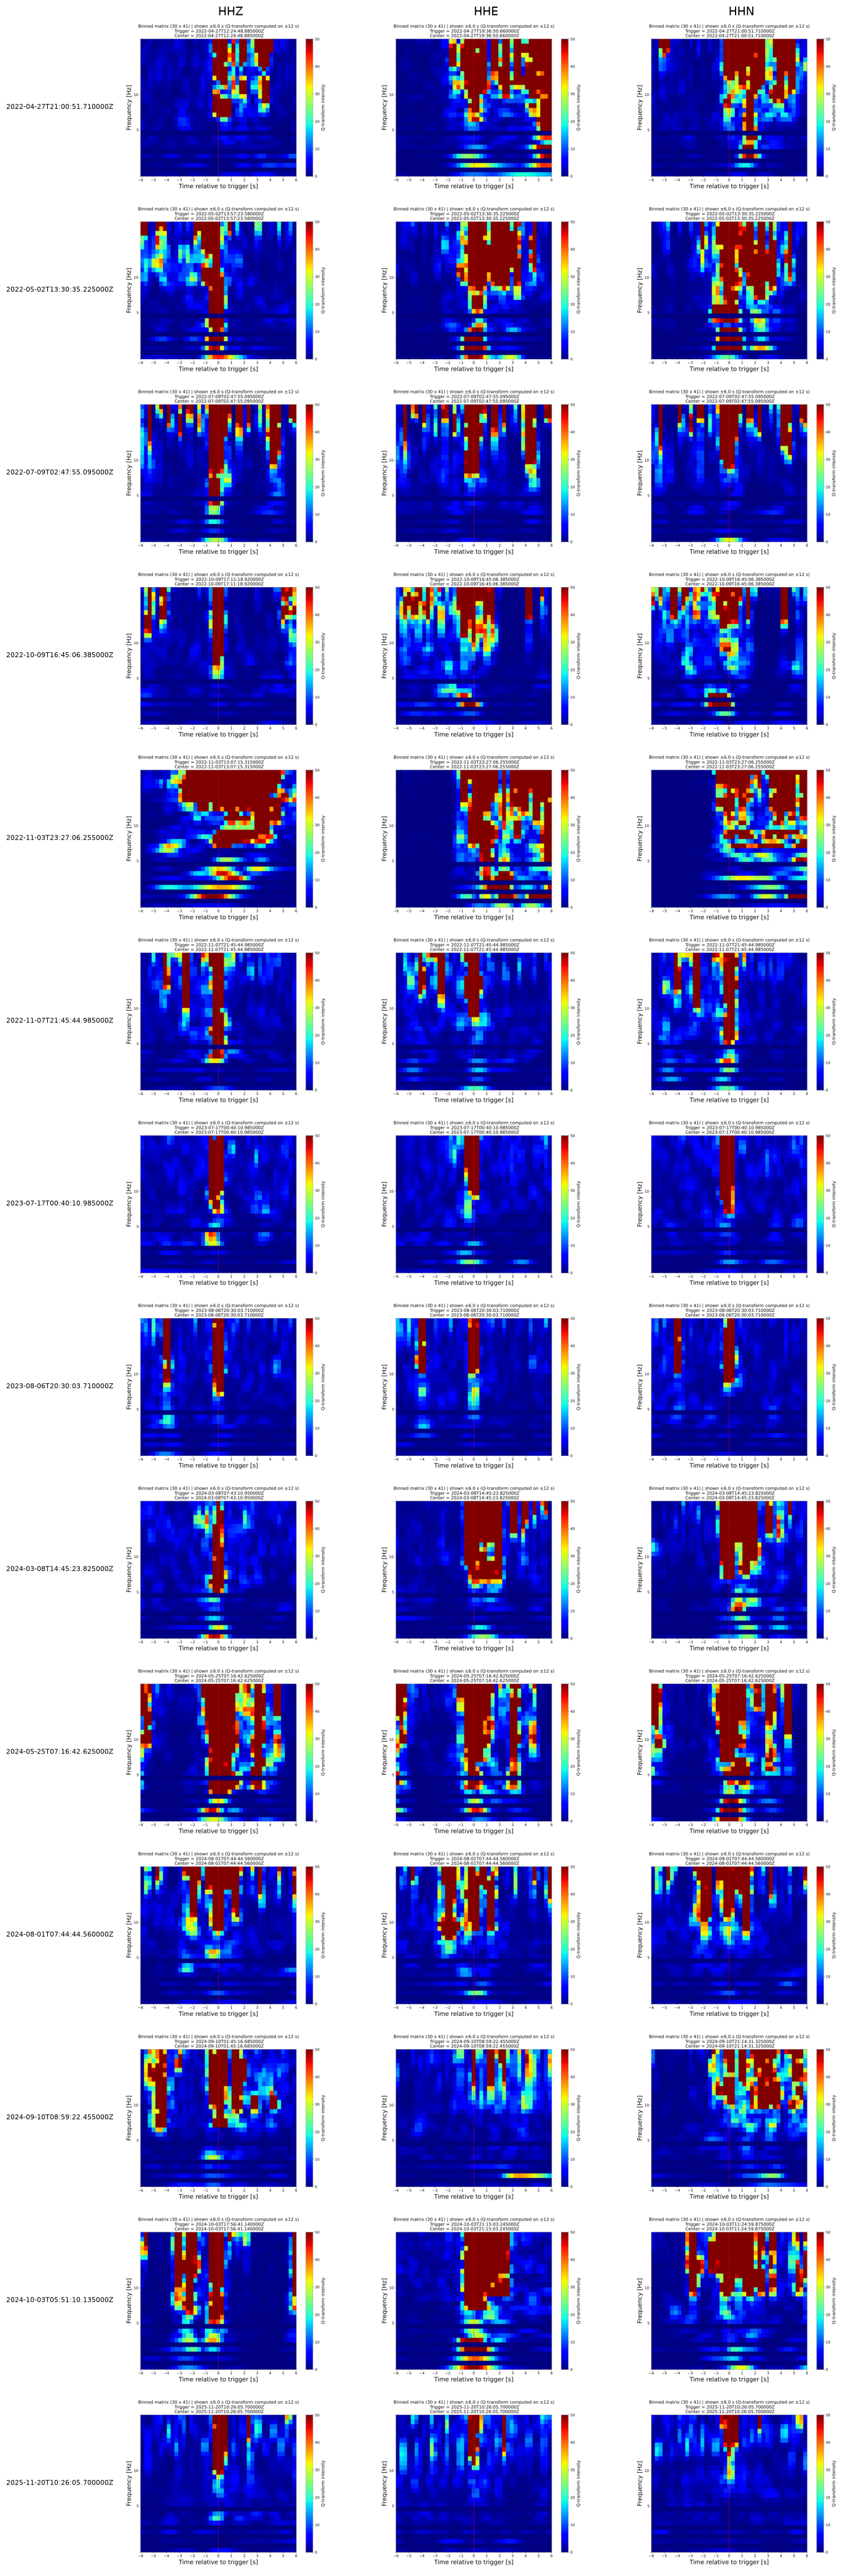

In [58]:
# New cell for terz_all_directions_2.ipynb (run it after the cells that define
# df_HHZ / df_HHE / df_HHN, RESULTS_ROOTS, DAY_KEY, qtransform_pdf_path and common_coherent).
# One row per trigger time, one column per channel, each cell = that channel's qtransform PDF.

try:
    import fitz  # PyMuPDF
    def pdf_to_array(path, dpi=80):
        with fitz.open(path) as doc:
            pix = doc[0].get_pixmap(dpi=dpi)
        return np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
except ImportError:
    from pdf2image import convert_from_path
    def pdf_to_array(path, dpi=80):
        return np.asarray(convert_from_path(path, dpi=dpi, first_page=1, last_page=1)[0])

CHANNELS = ["HHZ", "HHE", "HHN"]   # column order


def rows_for_triggers(df_ch, trigger_times):
    """Rows of ONE channel at the given trigger times, indexed by trigger_time, with the pdf_index of their PDF."""
    if "pdf_index" in df_ch.columns:
        pdf_index = df_ch["pdf_index"]
    else:  # per-day counter in dataframe order, computed on the FULL channel dataframe (not on the subset)
        pdf_index = df_ch.groupby(DAY_KEY).cumcount()
    sel = df_ch["trigger_time"].isin(trigger_times)
    return (df_ch.loc[sel].assign(pdf_index=pdf_index[sel])
                 .drop_duplicates("trigger_time").set_index("trigger_time"))


def plot_trigger_rows(trigger_times, dfs=None, dpi=80, width=5, height=3, save=None):
    dfs = dfs or {"HHZ": df_HHZ, "HHE": df_HHE, "HHN": df_HHN}
    rows = {ch: rows_for_triggers(dfs[ch], trigger_times) for ch in CHANNELS}

    fig, axes = plt.subplots(len(trigger_times), len(CHANNELS), squeeze=False,
                             figsize=(width * len(CHANNELS), height * len(trigger_times)))
    for i, t in enumerate(trigger_times):
        for j, ch in enumerate(CHANNELS):
            ax = axes[i, j]
            ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)

            msg = "no row for this trigger_time"
            if t in rows[ch].index:
                path = qtransform_pdf_path(rows[ch].loc[t])
                if path.exists():
                    ax.imshow(pdf_to_array(path, dpi))
                    msg = None
                else:
                    msg = "PDF not found"
                    print("missing:", path)
            if msg:
                ax.text(0.5, 0.5, msg, ha="center", va="center", transform=ax.transAxes)

            if i == 0:
                ax.set_title(ch, fontsize=14)
            if j == 0:
                ax.set_ylabel(str(t), rotation=0, ha="right", va="center", labelpad=10, fontsize=8)

    fig.tight_layout()
    if save:
        fig.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()


# trigger times present in all three directions (the same ones as df_coherent); change this list freely
trigger_times = sorted(common_coherent)[:14]
# random alternative: rng = np.random.default_rng(0); trigger_times = sorted(map(str, rng.choice(sorted(common_coherent), 5, replace=False)))
plot_trigger_rows(trigger_times)